<a href="https://colab.research.google.com/github/Drew-CSE/svd-image-transformation/blob/main/notebooks/04_which_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import subprocess
import sys

USER = "Drew-CSE"
REPO = "svd-image-transformation"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True
    )

sys.path.insert(0, f"{REPO}/src")

from compress import rank_k_approx, rel_error, predicted_error, compression_ratio
import numpy as np
import matplotlib.pyplot as plt

def k_for_error(s, target):
    """Smallest k whose relative error is at most target."""
    for k in range(1, len(s) + 1):
        if predicted_error(s, k) <= target:
            return k

1. This downloads or updates our repository and imports the compression functions. The k_for_error function finds the smallest k that meets a chosen relative error target.

2. I predict rank 1 for the horizontal stripes, rank 2 for the checkerboard, about rank 150 for the tilted stripes, about rank 50 for the disk, and rank 256 for the noise. I expect the horizontal stripes to compress best and the noise to compress worst.

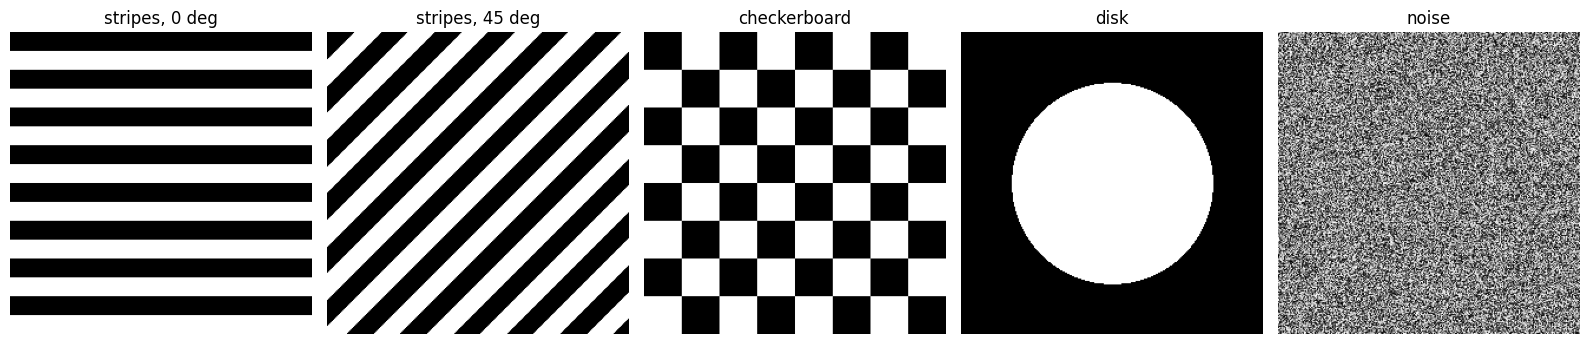

stripes, 0 deg   rank =   1 k for 5% =   1 ratio = 127.75
stripes, 45 deg  rank = 182 k for 5% =  64 ratio =   2.00
checkerboard     rank =   2 k for 5% =   2 ratio =  63.88
disk             rank =  51 k for 5% =  26 ratio =   4.91
noise            rank = 256 k for 5% = 198 ratio =   0.65


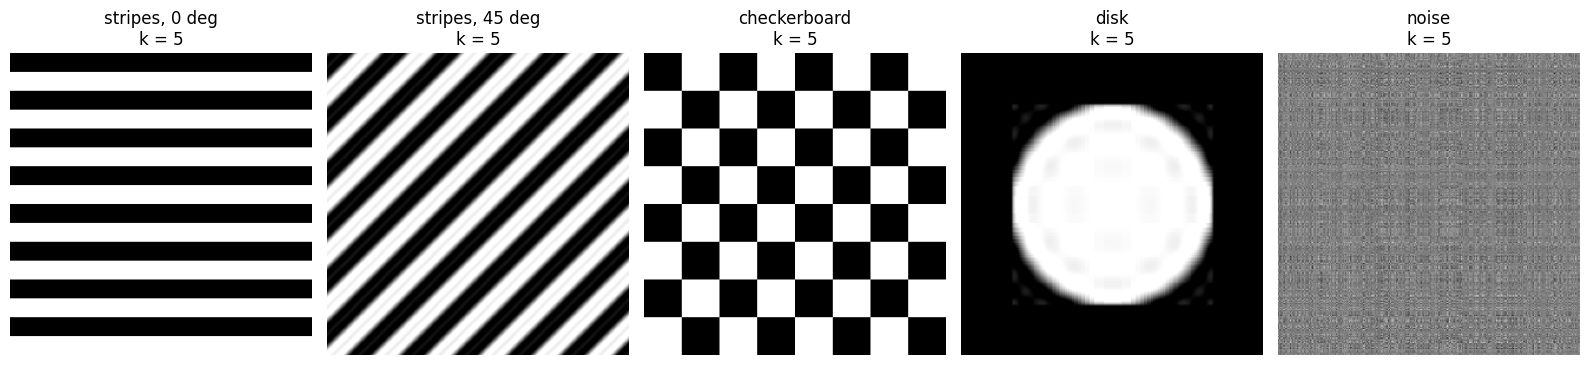

In [9]:
N = 256
i, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")

def stripes(angle, width=16):
    """Black and white stripes, tilted by angle degrees."""
    t = np.deg2rad(angle)
    return 255.0 * (
        np.floor((i * np.cos(t) + j * np.sin(t)) / width) % 2
    )

rng = np.random.default_rng(0)

patterns = {
    "stripes, 0 deg": stripes(0),
    "stripes, 45 deg": stripes(45),
    "checkerboard": 255.0 * ((i // 32 + j // 32) % 2),
    "disk": 255.0 * (
        (i - N/2)**2 + (j - N/2)**2 < (N/3)**2
    ),
    "noise": rng.integers(0, 256, size=(N, N)).astype(float),
}

# Display the original images.
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (name, P) in zip(axes, patterns.items()):
    ax.imshow(P, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Measure rank, k for 5% error, and compression ratio.
for name, P in patterns.items():
    s = np.linalg.svd(P, compute_uv=False)
    k5 = k_for_error(s, 0.05)
    print(
        f"{name:16s} rank = {np.linalg.matrix_rank(P):3d} "
        f"k for 5% = {k5:3d}"
        f" ratio = {compression_ratio(N, N, k5):6.2f}"
    )

# Display all five approximations at k = 5.
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (name, P) in zip(axes, patterns.items()):
    ax.imshow(
        np.clip(rank_k_approx(P, 5), 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(f"{name}\nk = 5")
    ax.axis("off")

plt.tight_layout()
plt.show()

This creates the five images, displays their originals, measures their compression, and displays their rank-5 approximations. The horizontal stripes and checkerboard compress well because their rows repeat. The tilted stripes and disk need more independent row patterns. Noise needs so many singular values that its SVD representation is larger than the original matrix at 5% error.

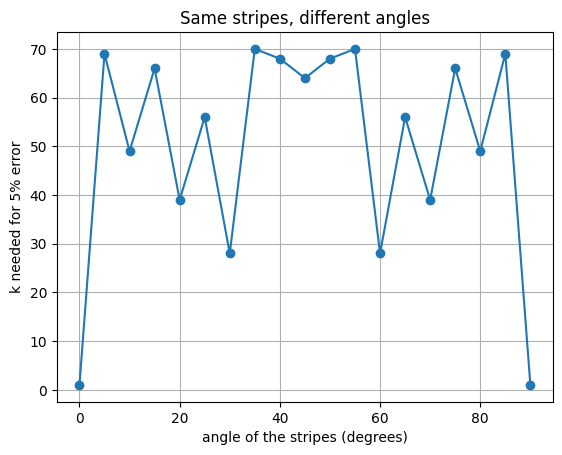

In [10]:
angles = np.arange(0, 91, 5)

ks = [
    k_for_error(
        np.linalg.svd(stripes(a), compute_uv=False),
        0.05
    )
    for a in angles
]

plt.plot(angles, ks, "o-")
plt.xlabel("angle of the stripes (degrees)")
plt.ylabel("k needed for 5% error")
plt.title("Same stripes, different angles")
plt.grid()
plt.savefig("angles.png", dpi=150)
plt.show()

3. This measures the k needed for 5% error as the stripes rotate. At 0 degrees, k = 1, but a 5 degree tilt increases it to k = 69. At 90 degrees, it returns to k = 1. Tilting the boundaries changes the row patterns, while the uneven changes between angles depend on how the boundaries cross the pixel grid.

4. Tilting a striped image by just 5 degrees increased the storage needed to stay within 5% error by a factor of 69, even though it still looked like the same basic stripe pattern.

In [11]:
print(stripes(45)[:4, :12] / 255)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


E1. The printed corner contains only zeros, so this small sample does not show the stripe boundaries. Across the full image, the boundaries shift sideways between rows. Many rows are shifted versions rather than scalar multiples of the preceding row because multiplication cannot move their zero entries. These changing row patterns explain the large rank.

E2. I will compare a normal checkerboard with a checkerboard tilted by 5 degrees. I predict that they will look similar, but the normal checkerboard will compress much better because its rows repeat. The tilted checkerboard should need a much larger k.

Normal checkerboard: k for 5% error = 2
Tilted checkerboard: k for 5% error = 95


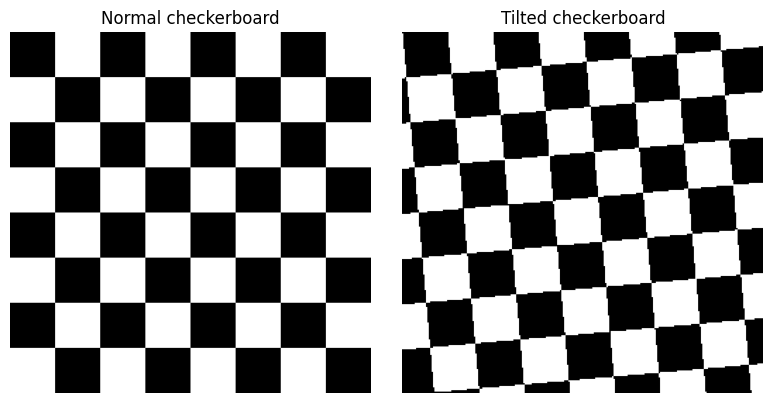

In [12]:
theta = np.deg2rad(5)

x_rot = i * np.cos(theta) + j * np.sin(theta)
y_rot = -i * np.sin(theta) + j * np.cos(theta)

good_image = 255.0 * ((i // 32 + j // 32) % 2)

bad_image = 255.0 * (
    (np.floor(x_rot / 32) + np.floor(y_rot / 32)) % 2
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, name, P in zip(
    axes,
    ["Normal checkerboard", "Tilted checkerboard"],
    [good_image, bad_image]
):
    ax.imshow(P, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

    s = np.linalg.svd(P, compute_uv=False)
    print(f"{name}: k for 5% error = {k_for_error(s, 0.05)}")

plt.tight_layout()
plt.show()

The prediction was correct. The normal checkerboard needs k = 2, while the tilted checkerboard needs k = 95 for 5% error. The images look similar, but tilting the checkerboard disrupts the repeating rows and makes compression much less effective.

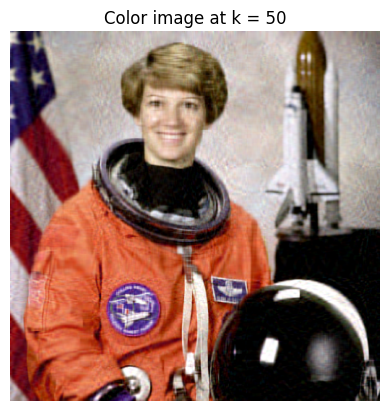

Relative error: 0.0773


In [13]:
from skimage import data

A = data.astronaut().astype(float)

channels = [
    rank_k_approx(A[:, :, c], 50)
    for c in range(3)
]

Ak = np.stack(channels, axis=2)
Ak = np.clip(Ak, 0, 255)

plt.imshow(Ak.astype(np.uint8))
plt.title("Color image at k = 50")
plt.axis("off")
plt.show()

print(f"Relative error: {rel_error(A, Ak):.4f}")

E3. This compresses each color channel at k = 50, stacks the channels together, and displays the result. The relative error is 0.0773.

At the same dimensions and k, a color approximation needs three times the storage of a grayscale approximation because it stores three sets of SVD factors. Each 512 by 512 channel needs 50(512 + 512 + 1) = 51,250 values, so all three channels need 153,750 values.

E4. At k = 5, the text image retains much of its overall brightness and broad structure but loses the thin strokes and sharp edges that distinguish letters. Relative error measures the total pixel difference, so it can remain small even when the details needed to read the text disappear.